# PPKS 04:  Simulacija odziva LTI sustava 

***

## Diskretni jedinični impuls i jedinični skok

Vremenski diskretan jedinični impuls definiramo na sljedeći način:
$$
\begin{equation}
  \delta[n] =
    \begin{cases}
      1 & n=0\\
      0 & \text{inače}
    \end{cases}       
\end{equation}
$$

što znači da impuls pomaknut u vremenu za $m$ uzoraka pišemo:
$$
\begin{equation}
  \delta[n-m] =
    \begin{cases}
      1 & n=m\\
      0 & \text{inače}
    \end{cases}       
\end{equation}
$$

Primjer implementacije jediničnog impulsa $\delta[n]$ dan je u nastavku. Definirana je diskretna vremenska os, a sam impuls je prikazan kao niz nula (funkcijom _np.zeros_like()_) s jedinicom u trenutku $n=0$. Funkcija _np.zeros_like(n)_ koristi se zato što automatski stvara niz nula istih dimenzija i tipa podataka kao postojeći niz $n$. Alternativa je _np.zeros()_, ali se na ovaj način izbjegava ručno zadavanje duljine niza i smanjuje mogućnost pogreške ako se $n$ promijeni. Osim toga, na ovaj način se osigurava usklađenost između indeksa i vrijednosti signala.

***

Vremenski diskretan jedinični skok definiramo s:
$$
\begin{equation}
  u[n] =
    \begin{cases}
      1 & n\ge0\\
      0 & \text{inače}
    \end{cases}       
\end{equation}
$$

Oznaka $u[n]$ dolazi od engleskog izraza _unit step_ kojim se označava takva funkcija, a često ju se naziva i po engleskom matematičaru i fizičaru Oliveru Heavisideu _Heaviside step function_. Pod tim nazivom možemo pronaći i funkciju u NumPy biblioteci: _np.heaviside(x1, x2)_. Ta funkcija za svaki element niza danog argumentom $x_1$ vraća vrijednost 0 ako je $n<0$, vrijednost 1 ako je 
$n>0$, dok za $n=0$ vraća vrijednost definiranu drugim argumentom ($x_2$). U ovom slučaju postavljamo $x_2 = 1$, čime dobivamo standardnu definiciju jediničnog skoka gdje je $u[0]=1$.
Implementacija jediničnog skoka tom funkcijom dana je u nastavku.


Text(0.5, 1.0, 'Diskretni jedinični skok u[n]')

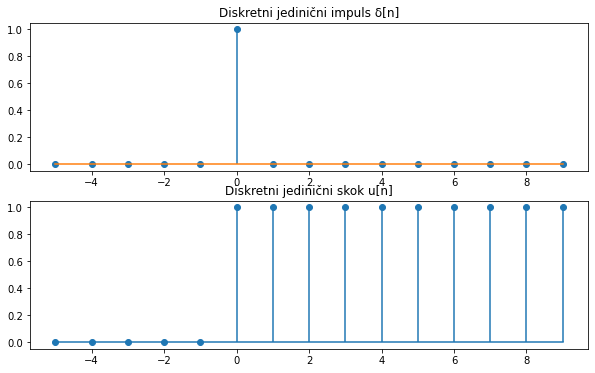

In [4]:
import numpy as np
import matplotlib.pyplot as plt

n = np.arange(-5, 10)  

delta_n = np.zeros_like(n)
delta_n[n == 0] = 1

u_n = np.heaviside(n, 1)    


plt.figure(figsize=(10,6))

plt.subplot(2,1,1)
plt.stem(n, delta_n, basefmt="C1-")
plt.title("Diskretni jedinični impuls δ[n]")

plt.subplot(2,1,2)
plt.stem(n, u_n, basefmt="C0-")
plt.title("Diskretni jedinični skok u[n]")




Jedinični impuls i jedinični skok su povezani. Kod diskretnih signala jedinični skok možemo zapisati kao sumu jediničnih impulsa pomaknutih u vremenu za $k$:
$$
u[n]=\sum_{k=0 }^{\infty }\delta[n-k]
$$

Ako pomaknemo granice sume, jedinični skok možemo zapisati i na sljedeći način:
$$
u[n]=\sum_{k=-\infty }^{n }\delta[k]
$$
To znači da se vrijednost $u[n]$ može dobiti sumiranjem svih impulsa koji su se pojavili od beskonačno daleke prošlosti do trenutka $n$. <br>
Objasnit ćemo kroz dvije opcije:
  - $n<0$:
    - Funkcija $u[n]$ tada uzima vrijednost $0$ jer je svaki član u sumi jednak $0$. Naime, jedinični impuls $\delta[k]$ je definiran tako da ima vrijednost $1$ samo u $k=0$, dok je svugdje drugdje $0$. Dakle, ako je $n<0$, u sumi ne postoji trenutak gdje bi impuls bio jednak $1$, pa cijela suma ostaje nula. To znači da je $u[n]=0$ za sve negativne $n$.

  - $n\ge0$:

    - Kad dođemo do $n=0$, tada se u sumi nalazi točno jedan impuls $\delta[0]=1$, što znači da je $u[0]=1$. 
    - Kad $n\ge 0$, tada se u sumi nalaze svi impulsi $\delta[k]$ za $k\le n$, uključujući onaj na $k=0$. No, budući da jedinični impuls samo u trenutku $k=0$ ima vrijednost $1$, ostatak sume ostaje nepromijenjen i $u[n]$ ostaje $1$ za sve $n\ge 0$.
        
Taj zapis nam je važan za analogiju s kontinuiranim signalima koju ćemo opisati kasnije.

S druge strane, jedinični impuls se može zapisati kao razlika dva jedinična skoka od kojih je jedan pomaknut u vremenu za $1$:
$$
\delta[n]=u[n]-u[n-1]
$$ 

U nastavku su prikazane implementacije jediničnog impulsa razlikom dva jedinična skoka (funkcija _np.diff()_) i jedinični skok sumom jediničnih impulsa (funkcija _np.cumsum()_).

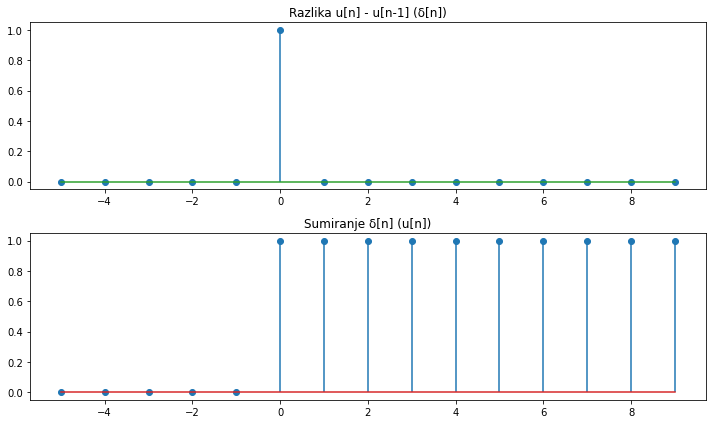

In [5]:
# Diskretna derivacija (diferencija)
du_n = np.diff(u_n, prepend=0)  
# np.diff(a, n=1); Calculate the n-th discrete difference along the given axis.
# a - ulaz, n=1 default; prepend - vrijednosti koje se dodaju prije racunanja
# np.diff(a) -> a[n+1]-a[n]

# Diskretna integracija (sumiranje)
sum_delta_n = np.cumsum(delta_n) # Return the cumulative sum of the elements along a given axis.

plt.figure(figsize=(10,6))

plt.subplot(2,1,1)
plt.stem(n, du_n, basefmt="C2-")
plt.title("Razlika u[n] - u[n-1] (δ[n])")

plt.subplot(2,1,2)
plt.stem(n, sum_delta_n, basefmt="C3-")
plt.title("Sumiranje δ[n] (u[n])")

plt.tight_layout()
plt.show()

## Veza između impulsa i skoka

Vremenski diskretan jedinični impuls u kontinuiranom svijetu predstavlja se __Diracovim impulsom__ $\delta(t)$ koji ima vrijednost $0$ u svim trenucima osim u $t=0$ kad poprima vrijednost $\infty $, a čiji je integral $=1$. 

Zapišimo Diracov impuls pomaknut za $a$ kao $\delta(t-a)$ pomoću pravokutnog impulsa širine $\epsilon$ i visine $\frac{1}{\epsilon}$:

$$
\delta_{\epsilon, a}(t) =
\begin{cases}
\frac{1}{\epsilon} & t \in (a, a+\epsilon) \\
0 & \text{inače}
\end{cases}
$$


Integral ove funkcije je:

$$
\int_{a}^{a+\epsilon} \frac{1}{\epsilon}\,dt
$$

$$
= \frac{1}{\epsilon} \int_{a}^{a+\epsilon} dt
= \frac{1}{\epsilon} \cdot (a+\epsilon - a)
= \frac{1}{\epsilon} \cdot \epsilon
= 1
$$

Vidimo da u slučaju kada $\epsilon \to 0$, pravokutni impuls postaje sve uži i viši (teži u $\infty$), a integral ostaje $=1$. Time dolazimo do idealnog Diracovog impulsa:

$$
\delta(t-a) = \lim_{\epsilon \to 0} \delta_{\epsilon, a}
$$



***


$\delta(t)$ možemo vizualizirati Gaussovom funkcijom:
$$
\delta_\sigma(t)=\frac{1}{\sigma\sqrt{2\pi}}e^{\frac{-t^2}{2\sigma}}
$$
gdje $\sigma$ određuje širinu impulsa, odnosno kad $\sigma\to0$, impuls u idealnom svijetu postaje beskonačno male širine i beskonačne visine, ali je njegov integral uvijek $=1$.

Integriranjem kontinuiranog impulsa do trenutka $t$ dobiva se kontinuirani jedinični skok:
$$
u(t)=\int_{-\infty }^{t }\delta(\tau)d\tau
$$
Ideja je slična kao i kod diskretnog jediničnog skoka: integral će za $t<0$ biti $=0$, a za $t>0$ će pokupiti cijeli jedinični impuls čiji je integral $=1$ pa će dalje za svaki $t\ge0\to u(t)=1$. U trenutku $t=0$, zbog prikaza impulsa Gaussovom distribucijom, $u(t=0)=0.5$. Vremena oko $t=0$ ovise o širini aproksimiranog jediničnog impulsa (o vrijednosti $\sigma$).

U suprotnom smjeru, kontinuirani jedinični impuls možemo zapisati kao derivaciju kontinuiranog jediničnog skoka jer taj skok ima veliku (_beskonačnu_) promjenu u trenutku $t=0$:
$$
\delta(t)=\frac{du(t)}{dt}
$$





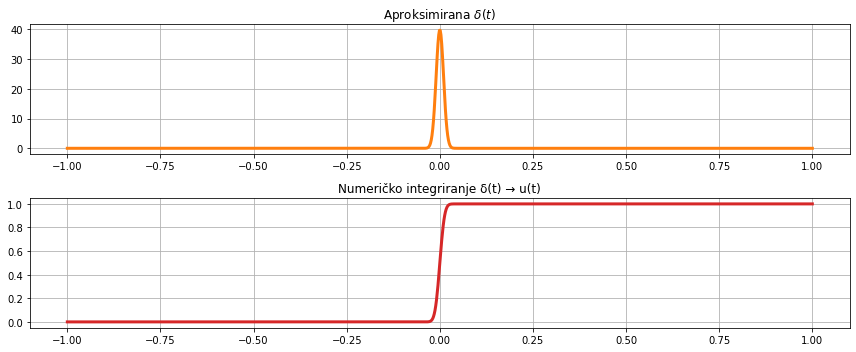

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import cumtrapz

# Definiranje "kontinuirane" vremenske osi
t = np.linspace(-1, 1, 1000)


sigma = 0.01  # Širina impulsa
delta_t = np.exp(-t**2 / (2 * sigma**2)) / (sigma * np.sqrt(2 * np.pi))

# Normalizacija tako da integral bude 1 (uvjet za Diracovu funkciju)
delta_t /= np.trapz(delta_t, t) # Integrate along the given axis using the composite trapezoidal rule.

# Numerička integracija Diracove funkcije (rekonstrukcija skoka)
integral_delta = cumtrapz(delta_t, t, initial=0)


plt.figure(figsize=(12,5))
plt.subplot(2,1,1)
plt.plot(t, delta_t, label="Aproksimirana $\delta(t)$", color="C1", linewidth=3)
plt.title("Aproksimirana $\delta(t)$")
plt.grid()

plt.subplot(2,1,2)
plt.plot(t, integral_delta, label="Integral δ(t)", color="C3", linewidth=3)
plt.title("Numeričko integriranje δ(t) → u(t)")
plt.grid()

plt.tight_layout()
plt.show()


***

## Analogija između kontinuiranih i diskretnih signala

Integral u kontinuiranom svijetu odgovara zbroju u diskretnom, a derivacija u kontinuiranom je diferencija (razlika vrijednosti dvaju susjednih uzoraka) u diskretnom svijetu. 

Razlog tome leži u načinu na koji se signali predstavljaju. Kontinuirani signali definirani su u svakom trenutku vremena, dok diskretni signali postoje samo u diskretnim vremenskim trenucima, odnosno uzorcima. Integral zbraja beskonačno male dijelove funkcije i predstavlja akumulaciju vrijednosti kroz vrijeme, dok suma u diskretnom vremenu ostvaruje isti učinak akumulirajući diskretne uzorke. 

Slično tome, derivacija mjeri promjenu funkcije u beskonačno malom intervalu kod kontinuiranih signala, dok konačna razlika aproksimira tu promjenu koristeći susjedne uzorke signala. Ova veza omogućuje prijenos metoda i koncepata iz kontinuirane u diskretnu domenu.

***

Pogledajmo prvo kako u kontinuiranoj domeni računamo derivaciju:

$$f'(t) = \lim_{\Delta t \to 0} \frac{f(t+\Delta t) - f(t)}{\Delta t}$$

Znamo da je derivacija nagib tangente (omjer promjene po $x$ osi i promjene po $y$ osi) na krivulju u točki $t$. Od te točke postavimo drugu točku po $x$ osi udaljenu za $\Delta t$. Dvije točke se nalaze na krivulji i imaju vrijednosti na $y$ osi u $f(t)$ i $f(t+\Delta t)$. Smanjujući udaljenost između te dvije točke ($\Delta t\to 0$), dobit ćemo omjer promjene po $y$ osi između vrijednosti i promjene po $x$ osi.


U diskretnom svijetu koristimo __diferenciju__. Kada signal nije definiran za sve vrijednosti $t \in \mathbb{R}$, nego samo za cijele indekse $n \in \mathbb{Z}$, limes više nema smisla. Najmanji mogući korak između dvije točke je jedan uzorak pa, bez limesa, ostaje samo razlika između vrijednosti dvaju susjednih uzoraka, a nju možemo gledati kroz dva pristupa:

$$\Delta x[n] = x[n+1] - x[n] $$
$$\Delta x[n] = x[n] - x[n-1] $$

U prvom pristupu koji zovemo __uzlazna diferencija__ računamo razliku između trenutnog $x[n]$ i sljedećeg $x[n+1]$ uzorka, a u drugom (__silazna diferencija__) razliku između trenutnog i prethodnog ($x[n-1]$). Drugi se pristup koristi u obradi signala u realnom vremenu.


***


**Primjer**

Pogledajmo funkciju $x(t)=t^2$. Znamo da je njezina derivacija $x'(t)=2t$. Ako računamo uzlaznu diferenciju u diskrenom svijetu za funkciju $x[n]=n^2$ dobit ćemo sljedeće:

$\Delta x[n] = x[n+1] - x[n] $

$\Delta x[n] = (n+1)^2 - n^2 $

$\Delta x[n] =  n^2+2n+1-n^2 $

$\Delta x[n] =  2n+1 $


U odnosu na derivaciju, kod diferencije imamo dodatni član ($+1$). Razlog tome je što u kontinuiranom svijetu derivacija mjeri promjenu u beskonačno malom koraku. Drugim riječima, promatra se što se događa kad je pomak $\Delta t \to 0$. U diskretnom slučaju ne postoji “beskonačno mali” pomak. Ovaj dodatni član pojavljuje se zato što je funkcija nelinearna, pa se između dvije točke mijenja ubrzano. Kod linearnih funkcija toga nema jer je promjena konstantna (nagib je isti u svakoj točki), pa su derivacija i diferencija jednake.






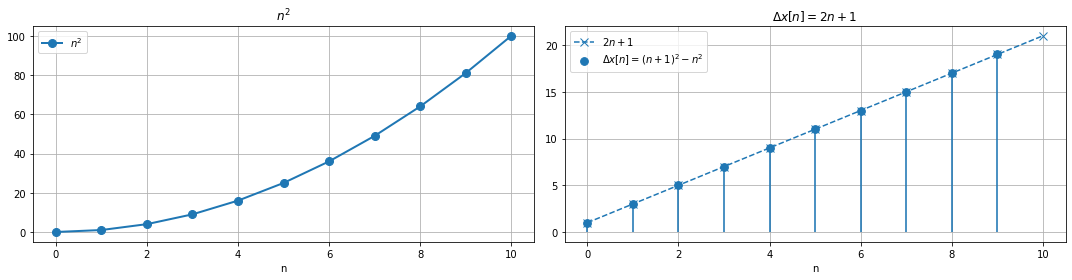

In [7]:
import numpy as np
import matplotlib.pyplot as plt

N = 10
n = np.arange(0, N + 1)
a = n**2

dx = np.diff(a)
ref = 2*n + 1

fig, axes = plt.subplots(1, 2, figsize=(15, 4))

axes[0].plot(n, a, 'o-', linewidth=2, markersize=8, label=r'$n^2$')
axes[0].set_title(r'$n^2$')
axes[0].set_xlabel('n')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(n, ref, 'x--', linewidth=1.5, markersize=8, label=r'$2n+1$')
axes[1].vlines(n[:-1], 0, df, linewidth=2, alpha=0.8)
axes[1].scatter(n[:-1], df, s=60, zorder=5, label=r'$\Delta x[n] = (n+1)^2 - n^2$')
axes[1].set_title(r'$\Delta x[n] = 2n+1$')
axes[1].set_xlabel('n')
axes[1].legend()
axes[1].grid(True)


plt.tight_layout()
plt.show()

***

## Što je sustav?

Općenito:  sustav preslikava ulaz u izlaz prema nekom pravilu:

$$
y[n]=\text{Pravilo}\{x[n]\}
$$
gdje je $x[n]$ ulaz, a $y[n]$ izlaz iz sustava.

Konkretnije, sustav može na ulaz dobivati zvuk, a na izlaz davati električni signal (kao mikrofon) ili dobivati diskretni ulazni signal $x[n]$, a davati pojačani taj signal $y[n]=2x[n]$.

Primjer takvog pojačala je dan u nastavku.

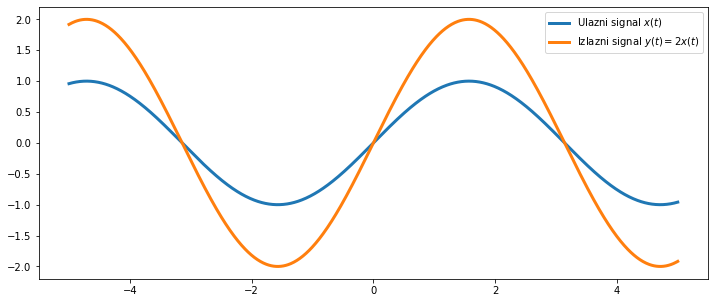

In [47]:
def Pojacalo(x):
    return 2*x   # the IO relation y(t)=2*x(t)

t = np.linspace(-5,5,1000)
x = np.sin(t)
y = Pojacalo(x)  # send x through the system


plt.figure(figsize=(12,5))
plt.plot(t, x, label='Ulazni signal $x(t)$', color="tab:blue", linewidth=3)
plt.plot(t, y, label='Izlazni signal $y(t)=2x(t)$', color="tab:orange", linewidth=3)

plt.legend()
plt.show()

Drugi primjer može biti sljedeći:
Sustav za ulaz $x[n]$ daje izlaz $y[n]=\frac{1}{5}\sum_{k=-2}^{2}x[n-k]$. 

Ako raspišemo tu sumu dobijemo:
$
y[n]=\frac{1}{5}[x[n+2]+x[n+1]+x[n]+x[n-1]+x[n-2]]
$

Sad vidimo da se radi o računanju prosjeka pet susjednih vrijednosti. Radi se o _Moving Average Filtru (MAF)_ s veličinom prozora $M=5$. MAF se koristi za smanjenje šuma i otklanjanje brzih promjena kako bi se istaknuli dugoročniji trendovi signala. Zbog svoje jednostavne implementacije i niske računalne složenosti, često se primjenjuje u digitalnoj obradi signala, financijama (za analizu tržišnih podataka), biomedicinskoj obradi signala (npr. filtriranje EKG-a) i industrijskim sustavima za uklanjanje mjernih grešaka. Dakle, i filtar je zapravo sustav koji na ulaz dobiva jedan, a daje drugi signal na izlazu. MAF je programski dan u nastavku.

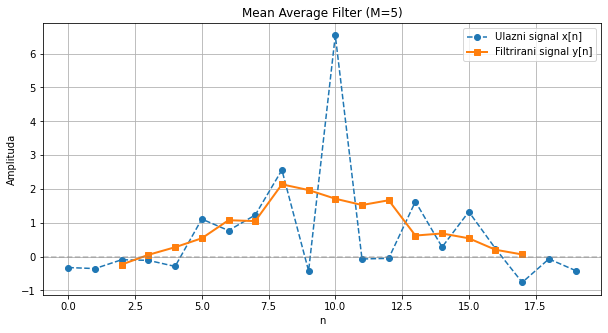

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Generiranje ulaznog signala (nasumični šum + impuls)
N = 20  # Duljina signala
x = np.random.randn(N)  # Nasumični signal
x[10] += 5  # Dodajemo impuls u sredini

M = 5  # Broj uzoraka u prozoru
y = np.convolve(x, np.ones(M)/M, mode='valid')  

n_x = np.arange(len(x))
n_y = np.arange(len(y)) + (M-1)//2  # Poravnavanje s originalnim signalom

# Crtanje signala
plt.figure(figsize=(10,5))
plt.plot(n_x, x, label="Ulazni signal x[n]", marker='o', linestyle='dashed')
plt.plot(n_y, y, label="Filtrirani signal y[n]", marker='s', linewidth=2)
plt.axhline(0, color='gray', linestyle='--', alpha=0.5)
plt.xlabel("n")
plt.ylabel("Amplituda")
plt.title("Mean Average Filter (M=5)")
plt.legend()
plt.grid()
plt.show()


## Karakteristike sustava

Prilikom analize sustava u obradi signala, važno je razumjeti ključne karakteristike koje definiraju njegovo ponašanje. Tri najvažnije karakteristike su 
 1. Kauzalnost
 2. Linearnost
 3. Invarijantnost na pomak
 
__Kauzalnost__<br>
Sustav je kauzalan ako izlaz u trenutku $n$ ovisi samo o sadašnjim i prošlim ulazima, ali ne i o budućim vrijednostima ulaza. Takvi sustavi mogu obrađivati signale u realnom vremenu. Prije spomenuti _Moving Average Filter_ nije kauzalan sustav jer, osim o prošlim vrijednostima (npr. $x[n-2]$), ovisi i o budućim (npr. $x[n+2]$). 

---

__Linearnost__<br>
Ako za ulaze $x_1[n]$ i $x_2[n]$ dobijemo izlaze $y_1[n]$ i $y_2[n]$, tada za sustav koji je linearan očekujemo sljedeće:

$$
a\cdot x_1[n]+b\cdot x_2[n]=a\cdot y_1[n]+b\cdot y_2[n]
$$

gdje su $a$ i $b$ skalari kojima množimo ulazne signale. Dakle, za sustav koji je linearan znamo da je svejedno skaliramo li ulazni signal prije provođenja kroz sustav ili skaliramo dobiveni izlaz (homogenost) i svejedno je zbrajamo li signale prije provođenja kroz sustav ili nakon provođenja jednostavno zbrojimo izlaze dobivene za pojedinačne ulaze (aditivnost).

Odnosno, sustav je linearan ako zadovoljava dva svojstva: 
 - __homogenost__: ako se ulaz pomnoži s nekim skalarom (npr. $a$), izlaz će se proporcionalno skalirati. <br>
   - za signal $x[n]$ koji nakon prolaska kroz linearni sustav $A$ daje $y[n]$ vrijedi:
$$
A\{ax[n]\} = ay[n]
$$

 - __aditivnost__: ako imamo dva ulaza, izlaz za njihovu sumu je jednak sumi pojedinačnih izlaza. 
   - za signale $x_1[n]$ i $x_2[n]$ koji nakon prolaska kroz linearni sustav $A$ daju izlaze $y_1[n]$ i $y_2[n]$ vrijedi:
$$
A\{x_1[n]+x_2[n]\}= y_1[n]+y_2[n]
$$

Linearnost nam omogućuje da ulaze rastavimo na jednostavnije komponente i provodimo ih kroz sustav zasebno što znatno pojednostavljuje obradu. Iako su mnogi fizički sustavi inherentno nelinearni, često ih možemo linearizirati kako bismo olakšali analizu i obradu podataka. Primjer linearnog sustava je prije spomenuto pojačalo $y[n]=2x[n]$, a primjer nelinearnog sustava bio bi kvadratni sustav koji radi $y[n]=x[n]^2$. Oba primjera su implementirana u nastavku.



---

__Invarijantnost na pomak__<br>
Sustav je invarijantan na pomak ako pomicanje ulaznog signala za $n_0$ rezultira istim pomakom na izlazu.

Za signal $x[n]$ koji nakon prolaska kroz sustav $A$ koji je invarijantan na pomak daje $y[n]$ vrijedi:

$$
A\{x[n-n_0]\}=y[n-n_0]
$$

Slično kao i kod linearnih sustava, za sustav koji je invarijantan na pomak očekujemo da je svejedno jesmo li zakasnili ulazni signal za $n_0$ uzoraka ili smo kroz sustav proveli nezakašnjeli signal $x[n]$ pa smo kasnije napravili pomak izlaza ($y[n] \rightarrow y[n-n_0]$).


Primjer sustava koji je invarijantan na pomak je $y[n]=x[n]-2x[n-1]$. To možemo provjeriti na način da prvo pogledamo kako bi se sustav ponašao kad izlaz pomaknemo za $n_0$:

$
y[n-n_0]=x[n-n_0]-2x[n-n_0-1]
$

Sada provjeravamo koji bi izlaz sustava bio ako ulazni signal pomaknemo za $n_0$ i takvog provedemo kroz sustav. To radimo definiranjem pomoćnog signala $z[n]=x[n-n_0]$. Kad taj signal provedemo kroz sustav dobit ćemo 

$
H\{z[n]\}=z[n]-2z[n-1]
$
, i onda uvrštavamo $z[n]=x[n-n_0]$:

$
H\{z[n]\}=x[n-n_0]-2x[n-n_0-1]
$

Vidimo da je isti rezultat bez obzira jesmo li pomaknuli izlaz $y$ za $n_o$ ili smo pomaknuli ulaz $x$ za $n_0$ pa ga proveli kroz sustav $H$.

Primjer sustava koji nije invarijantan na pomak je $y[n]=n \cdot x[n]$. Provjera invarijantnosti na pomak je ista kao u prethodnom primjeru.


***

## LTI sustavi

Sustave koji su linearni i invarijantni na pomak zovemo __LTI sustavima__ (eng. _Linear, Time-Invariant Systems_). Takvi sustavi imaju zanimljiva svojstva poput toga da su u potpunosti određeni svojim __impulsnim odzivom__. U nastavku je opisano što to znači.




***

### Provjera linearnosti

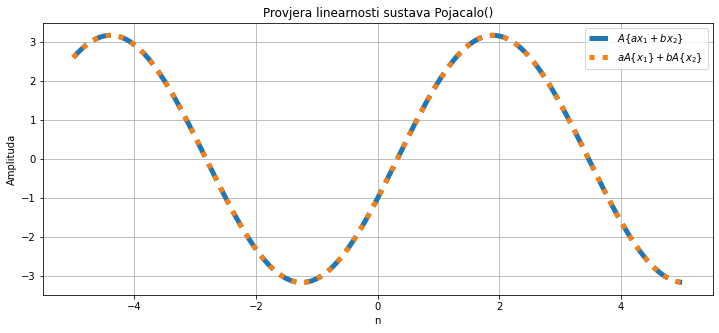

In [4]:
import numpy as np
import matplotlib.pyplot as plt

def Pojacalo(x):
    return 2 * x  # y(n) = 2 * x(n)

n = np.linspace(-5, 5, 1000)

x1 = np.sin(n)          # Prvi signal
x2 = np.cos(n)          # Drugi signal
a, b = 1.5, -0.5        # Skalari

lhs = Pojacalo(a * x1 + b * x2)  # Lijeva strana: A{a x1 + b x2}
rhs = a * Pojacalo(x1) + b * Pojacalo(x2)  # Desna strana: a A{x1} + b A{x2}

plt.figure(figsize=(12,5))
plt.plot(n, lhs, label=r'$A\{a x_1 + b x_2\}$', linestyle='dashed', color="tab:blue", linewidth=5)
plt.plot(n, rhs, label=r'$a A\{x_1\} + b A\{x_2\}$', linestyle='dotted', color="tab:orange", linewidth=5)

plt.legend()
plt.title("Provjera linearnosti sustava Pojacalo()")
plt.xlabel("n")
plt.ylabel("Amplituda")
plt.grid()
plt.show()





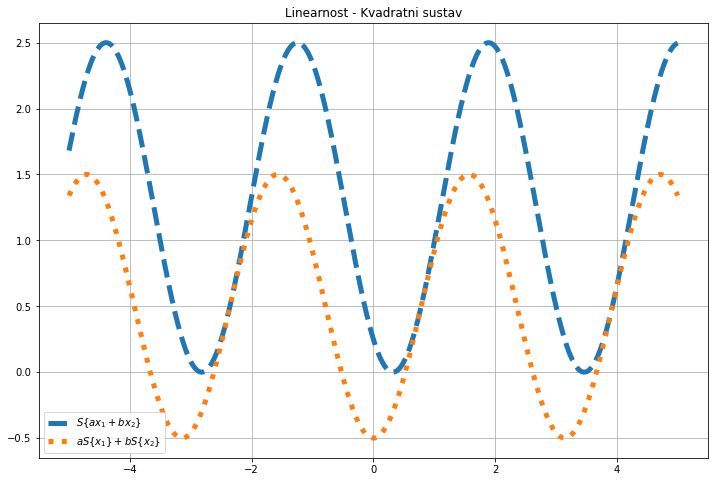

In [5]:
import numpy as np
import matplotlib.pyplot as plt


def KvadratniSustav(x):  # y(n) = x^2(n)
    return x ** 2

n = np.linspace(-5, 5, 1000)

# Ulazni signali
x1 = np.sin(n)
x2 = np.cos(n)
a, b = 1.5, -0.5  # Skalari

lhs_kvadratni = KvadratniSustav(a * x1 + b * x2)
rhs_kvadratni = a * KvadratniSustav(x1) + b * KvadratniSustav(x2)

plt.figure(figsize=(12,8))

plt.plot(n, lhs_kvadratni, label=r'$S\{a x_1 + b x_2\}$', linestyle='dashed', color="tab:blue", linewidth=5)
plt.plot(n, rhs_kvadratni, label=r'$a S\{x_1\} + b S\{x_2\}$', linestyle='dotted', color="tab:orange", linewidth=5)
plt.title("Linearnost - Kvadratni sustav")
plt.legend()
plt.grid()

plt.show()





***

### Provjera invarijantnosti na pomak

y[n] = x[n] - 2x[n-1]
y[n] = n * x[n] 


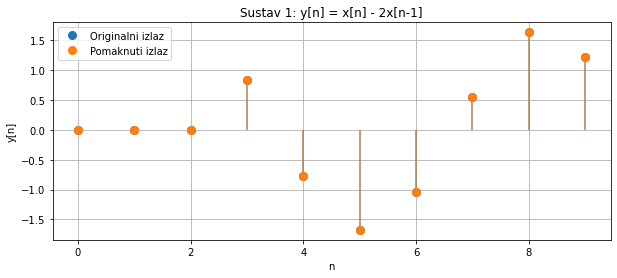

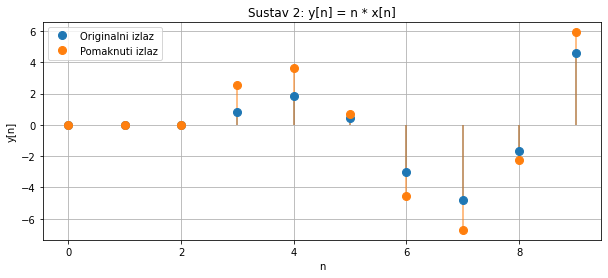

In [6]:
import numpy as np
import matplotlib.pyplot as plt

def system1(x):
   # Sustav: y[n] = x[n] - 2*x[n-1]
    
    y = np.zeros_like(x)
    y[0] = x[0]  # Pretpostavka za prvi element (nema n-1)
    y[1:] = x[1:] - 2*x[:-1]  # Primjena definicije sustava
    return y

def system2(x, n):
    #    Sustav: y[n] = n * x[n]
    return n * x

n = np.arange(10)
x = np.sin(n)  

# Pomak za k = 2
k = 2
x_shifted = np.roll(x, k)
x_shifted[:k] = 0  # Nullify the new values at the beginning

# Provjera invarijantnosti sustava 1
y_original_1 = system1(x)
y_shifted_1 = system1(x_shifted)

y_original_1_shifted = np.roll(y_original_1, k)
y_original_1_shifted[:k] = 0  # Nullify to match causality

print(f"y[n] = x[n] - 2x[n-1]")

# Provjera invarijantnosti sustava 2
y_original_2 = system2(x, n)
y_shifted_2 = system2(x_shifted, n)

y_original_2_shifted = np.roll(y_original_2, k)
y_original_2_shifted[:k] = 0  # Nullify to match causality

print(f"y[n] = n * x[n] ")

def plot_signals(n, original, shifted, title):
    plt.figure(figsize=(10,4))
    markerline1, stemlines1, _ = plt.stem(n, original, basefmt=' ', label='Originalni izlaz')
    plt.setp(stemlines1, color='tab:blue', linewidth=2, alpha=0.5)
    plt.setp(markerline1, color='tab:blue', markersize=8)
    
    markerline2, stemlines2, _ = plt.stem(n, shifted, basefmt=' ', label='Pomaknuti izlaz')
    plt.setp(stemlines2, color='tab:orange', linewidth=2, alpha=0.5)
    plt.setp(markerline2, color='tab:orange', markersize=8)
    
    plt.xlabel("n")
    plt.ylabel("y[n]")
    plt.title(title)
    plt.legend()
    plt.grid()
    plt.show()

plot_signals(n, y_original_1_shifted, y_shifted_1, "Sustav 1: y[n] = x[n] - 2x[n-1]")
plot_signals(n, y_original_2_shifted, y_shifted_2, "Sustav 2: y[n] = n * x[n]")


***

## Impulsni odziv

Jedna od glavnih prednosti LTI sustava je mogućnost korištenja impulsnog odziva za karakterizaciju drugih odziva. U nastavku ćemo objasniti što je to impulsni odziv i zašto je važan za komunikacijske sustave.

Signal $x[n]$ možemo prikazati kao zbroj jediničnih impulsa na način da svaki impuls (koji pomičemo u vremenu) množimo s vrijednošću signala $x[n]$ u tom trenutku. To pišemo na sljedeći način:

$$
x[n]=a_0\cdot \delta[n]+a_1\cdot \delta[n-1]+a_2\cdot \delta[n-2]...
$$
gdje je $a_k$ vrijednost signala $x[n]$ na uzorku $k$, odnosno možemo ga shvatiti kao skalar koji množi signal $\delta[n-k]$ (impuls koji je pomaknut u vremenu za $k$).

To možemo zapisati u obliku sume:
$$
x[n]=\sum_{k=-\infty}^{\infty}x[k]\delta[n-k]
$$

Signal $x[n]$ smo rastavili na pomaknute $\delta$ signale koje množimo skalarima. __Zašto nam je to zanimljivo?__
***
Pitanje je što bi se dogodilo ako na ulaz nekog sustava $H$ dovedemo jedinični impuls $\delta[n]$.
Označimo signal koji sustav daje kao izlaz u tom slučaju $h[n]$. Taj signal zvat ćemo __impulsni odziv__. 
Signal impulsnog odziva tada pišemo:
$$
h[n]=H\{\delta [n]\}
$$

Dovedimo sad na ulaz tog istog sustava $H$ neki proizvoljni signal $x[n]$. Izlaz sustava za taj signal prikazujemo s $y[n]=H\{x[n]\}$.

Ako ulazni signal $x[n]$ zapišemo koristeći prije spomenuti zapis u obliku sume jediničnih impulsa, izlaz je zapravo:
$$
y[n]=H\left \{\sum_{k=-\infty}^{\infty}x[k]\delta[n-k] \right \}
$$

Budući da se radi o LTI sustavu znamo da je naš sustav $H$ linearan pa možemo prije provođenja cijelog izraza kroz sustav izvući van dio koji u tom slučaju predstavljaju konstante (skalare). Odnosno sustav $H$ sad djeluje samo na jedinični impuls pomaknut za $k$:
$$
y[n]=\sum_{k=-\infty}^{\infty}x[k]\cdot H\{\delta[n-k]\}
$$

Na sličan način, budući da je sustav $H$ invarijantan na pomak, isto je radimo li pomak za $k$ uzoraka prije ili nakon provođenja jediničnog impulsa kroz sustav: $H\{\delta[n-k]\}=h[n-k]$<br>
Cijeli izraz sad možemo zapisati pomoću pomaknutog impulsnog odziva:
$$
y[n]=\sum_{k=-\infty}^{\infty}x[k]\cdot h[n-k]
$$

A taj izraz zapravo predstavlja __konvoluciju__ ulaznog signala $x[n]$ i impulsnog odziva $h[n]$:
$$
y[n]=x[n]*h[n]
$$

Dakle, izlaz LTI sustava za bilo koji ulazni signal $x[n]$ je konvolucija tog signala s izlazom sustava za jedinični impuls, odnosno s impulsnim odzivom $h[n]$. Ako znamo impulsni odziv LTI sustava, onda za svaki ulazni signal točno znamo koji izlaz očekujemo. 

Jedna od primjena kojom se to može intuitivnije shvatiti je zvučni odziv na pljesak u nekoj prostoriji. Pljesak u tom slučaju predstavlja jedinični impuls, a reakcija prostorije na pljesak (snimka zvuka u toj prostoriji) je impulsni odziv. Kad imamo tu snimku, za bilo koji drugi zvuk (npr. govor ili glazbu) možemo konvolucijom tog zvuka sa snimkom pljeska saznati kako će se čuti u toj prostoriji.

